# DISEASE: HYPERTENSION

### 1.1. Reading the Dataset

### 1.2. General Information

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("C:/Users/User/Documents/diploma/data/datasets_original/Hypertension-risk-model-main.csv")

print(df.shape)
df.info()

(4240, 13)
<class 'pandas.DataFrame'>
RangeIndex: 4240 entries, 0 to 4239
Data columns (total 13 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   male           4240 non-null   int64  
 1   age            4240 non-null   int64  
 2   currentSmoker  4240 non-null   int64  
 3   cigsPerDay     4211 non-null   float64
 4   BPMeds         4187 non-null   float64
 5   diabetes       4240 non-null   int64  
 6   totChol        4190 non-null   float64
 7   sysBP          4240 non-null   float64
 8   diaBP          4240 non-null   float64
 9   BMI            4221 non-null   float64
 10  heartRate      4239 non-null   float64
 11  glucose        3852 non-null   float64
 12  Risk           4240 non-null   int64  
dtypes: float64(8), int64(5)
memory usage: 430.8 KB


### 2. Missing values

In [2]:
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
pd.DataFrame({"missing": missing, "pct": missing_pct}).query("missing > 0")

,missing,pct
cigsPerDay,29,0.68
BPMeds,53,1.25
totChol,50,1.18
BMI,19,0.45
heartRate,1,0.02
glucose,388,9.15


### 3. Summary stats

In [3]:
df.describe(include="all").T

,count,mean,std,min,25%,50%,75%,max
male,4240.0,0.429245,0.495027,0.00,0.00,0.0,1.00,1.0
age,4240.0,49.580189,8.572942,32.00,42.00,49.0,56.00,70.0
currentSmoker,4240.0,0.494104,0.500024,0.00,0.00,0.0,1.00,1.0
cigsPerDay,4211.0,9.005937,11.922462,0.00,0.00,0.0,20.00,70.0
BPMeds,4187.0,0.029615,0.169544,0.00,0.00,0.0,0.00,1.0
diabetes,4240.0,0.025708,0.158280,0.00,0.00,0.0,0.00,1.0
totChol,4190.0,236.699523,44.591284,107.00,206.00,234.0,263.00,696.0
sysBP,4240.0,132.354599,22.033300,83.50,117.00,128.0,144.00,295.0
diaBP,4240.0,82.897759,11.910394,48.00,75.00,82.0,90.00,142.5
BMI,4221.0,25.800801,4.079840,15.54,23.07,25.4,28.04,56.8


### 3.1. Target balance

In [2]:
df["Risk"].value_counts(normalize=True).mul(100).round(2)

Risk
0    68.94
1    31.06
Name: proportion, dtype: float64

### 3.2. Duplicates

In [2]:
print("Exact duplicates:", df.duplicated().sum())

Exact duplicates: 0


### 4. Correlation matrix

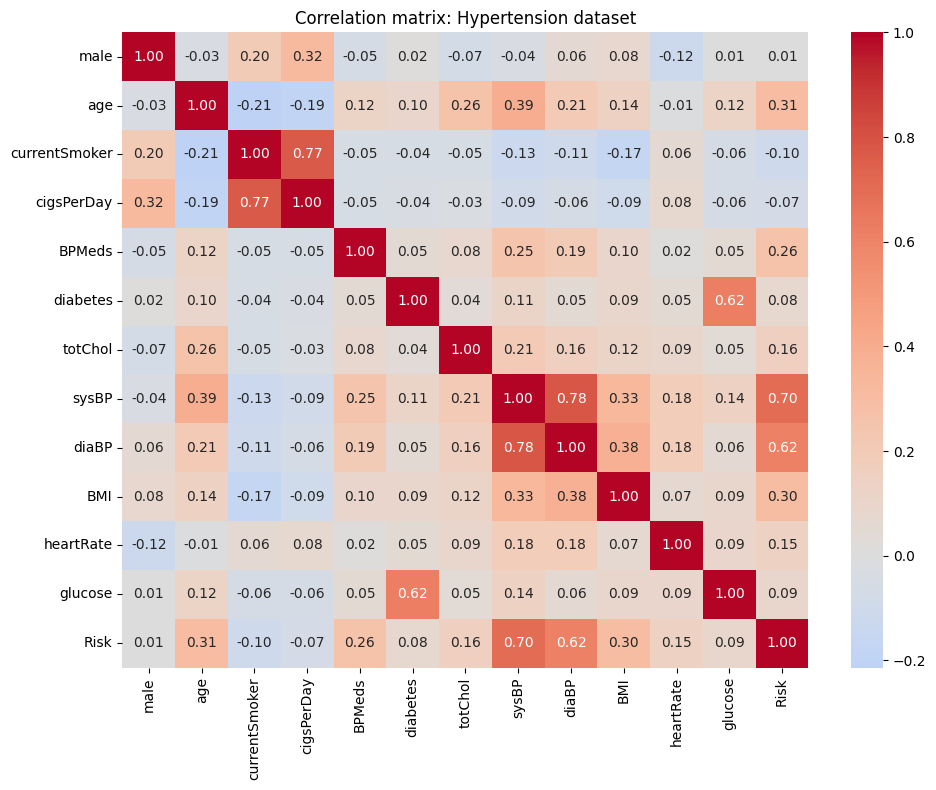

In [4]:
corr = df.select_dtypes(include="number").corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix: Hypertension dataset")
plt.tight_layout()
plt.show()

### 5. Correlation with target, sorted

In [5]:
target = "Risk"
corr[target].drop(target).sort_values(key=abs, ascending=False)

sysBP            0.696656
diaBP            0.615840
age              0.306799
BMI              0.301344
BPMeds           0.261067
totChol          0.163632
heartRate        0.146815
currentSmoker   -0.103710
glucose          0.086656
diabetes         0.077752
cigsPerDay      -0.066645
male             0.005853
Name: Risk, dtype: float64